# House Prices — Dò và so sánh 6 mô hình trên 79 đặc trưng gốc

CV lồng nhau dùng 5 fold ngoài như thí nghiệm cấu hình cố định và 3 fold trong để chọn siêu tham số. Mỗi vòng tìm kiếm chỉ nhận phần train của fold ngoài. RMSE trên ln(SalePrice) của fold ngoài được dùng để so sánh với điểm đã lưu của cấu hình cố định. DummyRegressor dùng strategy=mean làm mốc.

## Cấu hình cố định và lưới dò

In [1]:
EXPERIMENT_NAME = "14-11-2026_6model_79_nested_cv_phuc"
RANDOM_STATE = 42
N_SPLITS = 5

MODEL_PARAMS = {
    "DummyRegressor": {"strategy": "mean"},
    "Ridge": {"alpha": 1.0, "solver": "lsqr"},
    "Random Forest": {"n_estimators": 200, "min_samples_leaf": 2, "random_state": RANDOM_STATE},
    "Lasso": {"alpha": 0.001, "max_iter": 10000},
    "XGBoost": {"n_estimators": 200, "max_depth": 4, "learning_rate": 0.05,
                "random_state": RANDOM_STATE, "n_jobs": 2},
    "SVR": {"C": 10.0, "epsilon": 0.05, "gamma": "scale"},
}

INNER_SPLITS = 3
PARAM_GRID = {
    "DummyRegressor": {},
    "Ridge": {"alpha": [0.1, 1.0, 10.0, 30.0]},
    "Random Forest": {"min_samples_leaf": [1, 2, 4], "max_features": [1.0, 0.5]},
    "Lasso": {"alpha": [0.0003, 0.001, 0.002, 0.005]},
    "XGBoost": {"max_depth": [2, 4], "learning_rate": [0.03, 0.05, 0.1]},
    "SVR": {"C": [1.0, 10.0, 30.0], "epsilon": [0.02, 0.05, 0.1]},
}

## Dữ liệu và split

Cần kernel có scikit-learn và xgboost hoặc xgboost-cpu.

In [2]:
import json
import sys
import warnings
from datetime import datetime, timedelta, timezone
from pathlib import Path
from time import perf_counter

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.base import clone
from sklearn.metrics import root_mean_squared_error
from sklearn.model_selection import KFold
from sklearn.pipeline import make_pipeline

cwd = Path.cwd().resolve()
project = next(
    path for path in (cwd, *cwd.parents, cwd / "Challenge1_House Prices_ Advanced Regression")
    if (path / "src" / "prepare_data.py").is_file()
    and (path / "data" / "raw" / "train.csv").is_file()
)
sys.path.insert(0, str(project))

from src.model import make_lasso, make_svr, make_xgboost
from src.models import make_dummy, make_random_forest, make_ridge
from src.prepare_data import DATA_DIR, ID, TARGET, extract_features, make_preprocessor
from sklearn.model_selection import GridSearchCV

In [3]:
train = pd.read_csv(DATA_DIR / "raw" / "train.csv")
X = extract_features(train)
prices = train[TARGET]
assert X.shape[1] == 79, f"Cần 79 đặc trưng gốc, hiện có {X.shape[1]}"
assert np.isfinite(prices).all() and prices.gt(0).all()
y = np.log(prices)

cv = KFold(n_splits=N_SPLITS, shuffle=True, random_state=RANDOM_STATE)
splits = list(cv.split(X))
predictions = pd.DataFrame({ID: train[ID], "ln_SalePrice": y})
predictions["fold"] = 0
for fold, (_, valid_idx) in enumerate(splits, 1):
    predictions.loc[valid_idx, "fold"] = fold

display(predictions.groupby("fold").size().rename("Số mẫu validation").to_frame())

baseline_dir = (
    project / "experiments" / "14-11-2026_6model_79_phuc"
    / "outputs" / "20261114_224507_500186"
)
baseline_predictions = pd.read_csv(baseline_dir / "validation_predictions.csv")
assert predictions[[ID, "fold"]].equals(baseline_predictions[[ID, "fold"]])
np.testing.assert_allclose(predictions["ln_SalePrice"], baseline_predictions["ln_SalePrice"])
fixed = pd.read_csv(baseline_dir / "validation_metrics.csv").set_index("model")
fold_columns = [f"fold{i}" for i in range(1, N_SPLITS + 1)]

,Số mẫu validation
fold,
1,292
2,292
3,292
4,292
5,292


## Dò trong fold train và đánh giá trên fold ngoài

In [4]:
factories = {
    "DummyRegressor": make_dummy,
    "Ridge": make_ridge,
    "Random Forest": make_random_forest,
    "Lasso": make_lasso,
    "XGBoost": make_xgboost,
    "SVR": make_svr,
}
inner = KFold(n_splits=INNER_SPLITS, shuffle=True, random_state=RANDOM_STATE)
scoring = "neg_root_mean_squared_error"
fold_rows = []
candidate_rows = []
for name, factory in factories.items():
    for fold, (fit_idx, valid_idx) in enumerate(splits, 1):
        started = perf_counter()
        pipeline = make_pipeline(make_preprocessor(X), factory(**MODEL_PARAMS[name]))
        # make_pipeline đặt tên bước theo lớp estimator.
        step = pipeline.steps[-1][0]
        estimator_grid = {f"{step}__{key}": values
                          for key, values in PARAM_GRID[name].items()}
        X_train, y_train = X.iloc[fit_idx], y.iloc[fit_idx]
        best_params, inner_rmse = {}, None
        if estimator_grid:
            search = GridSearchCV(
                pipeline, estimator_grid, scoring=scoring, cv=inner,
                n_jobs=1, refit=True, error_score="raise",
            )
            search.fit(X_train, y_train)
            fitted = search.best_estimator_
            best_params = {key.split("__", 1)[1]: value
                           for key, value in search.best_params_.items()}
            inner_rmse = -search.best_score_
            for params, score, rank in zip(search.cv_results_["params"],
                                           search.cv_results_["mean_test_score"],
                                           search.cv_results_["rank_test_score"]):
                candidate_rows.append({
                    "model": name, "fold": fold,
                    "params": json.dumps({key.split("__", 1)[1]: value
                                          for key, value in params.items()}),
                    "inner_rmse": -score, "inner_rank": rank,
                })
        else:
            fitted = pipeline.fit(X_train, y_train)
        predicted = fitted.predict(X.iloc[valid_idx])
        predictions.loc[valid_idx, name] = predicted
        outer_rmse = root_mean_squared_error(y.iloc[valid_idx], predicted)
        fixed_rmse = fixed.loc[name, f"fold{fold}"]
        fold_rows.append({
            "model": name, "fold": fold, "best_params": json.dumps(best_params),
            "inner_rmse": inner_rmse, "fixed_rmse": fixed_rmse, "tuned_rmse": outer_rmse,
            "delta_rmse": outer_rmse - fixed_rmse,
            "elapsed_seconds": perf_counter() - started,
        })
    print(f"{name}: xong 5 fold ngoài", flush=True)

fold_results = pd.DataFrame(fold_rows)
assert predictions[list(factories)].notna().all().all()

DummyRegressor: xong 5 fold ngoài
Ridge: xong 5 fold ngoài
Random Forest: xong 5 fold ngoài
Lasso: xong 5 fold ngoài
XGBoost: xong 5 fold ngoài
SVR: xong 5 fold ngoài


## So sánh

Delta = RMSE sau dò trừ RMSE cấu hình cố định. Delta âm nghĩa là RMSE giảm.

,fixed_rmse_mean,tuned_rmse_mean,tuned_rmse_std,delta_rmse_mean
model,,,,
XGBoost,0.13351,0.13322,0.02039,-0.00028
SVR,0.14284,0.13777,0.01515,-0.00507
Random Forest,0.14487,0.14045,0.02032,-0.00441
Ridge,0.14793,0.14603,0.04498,-0.00190
Lasso,0.14362,0.14616,0.04731,0.00254
DummyRegressor,0.39878,0.39878,0.02810,0.00000


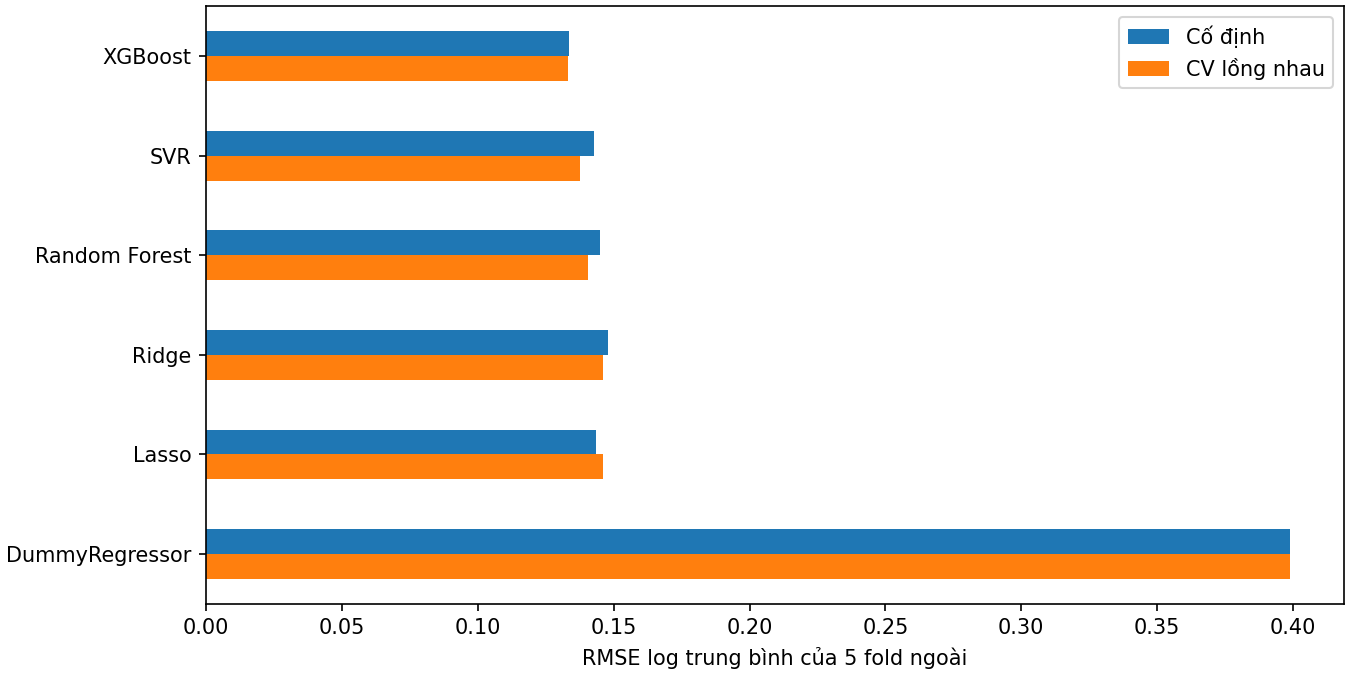

In [5]:
comparison = fold_results.groupby("model").agg(
    fixed_rmse_mean=("fixed_rmse", "mean"),
    tuned_rmse_mean=("tuned_rmse", "mean"),
    tuned_rmse_std=("tuned_rmse", "std"),
    delta_rmse_mean=("delta_rmse", "mean"),
).sort_values("tuned_rmse_mean")
display(comparison.round(5))

fig, ax = plt.subplots(figsize=(9, 4.5), layout="constrained")
comparison[["fixed_rmse_mean", "tuned_rmse_mean"]].rename(columns={
    "fixed_rmse_mean": "Cố định",
    "tuned_rmse_mean": "CV lồng nhau",
}).plot.barh(ax=ax)
ax.invert_yaxis()
ax.set(xlabel="RMSE log trung bình của 5 fold ngoài", ylabel="")
plt.show()

## Lưu kết quả

In [6]:
run_time = datetime.now(timezone(timedelta(hours=7)))
run_dir = project / "experiments" / EXPERIMENT_NAME / "outputs" / run_time.strftime("%Y%m%d_%H%M%S_%f")
run_dir.mkdir(parents=True, exist_ok=False)
comparison.to_csv(run_dir / "comparison.csv")
fold_results.to_csv(run_dir / "outer_fold_results.csv", index=False)
pd.DataFrame(candidate_rows).to_csv(run_dir / "inner_grid_results.csv", index=False)
predictions.to_csv(run_dir / "validation_predictions.csv", index=False)
config = {
    "baseline": str(baseline_dir.relative_to(project)),
    "feature_columns": X.columns.tolist(),
    "target": "ln(SalePrice)",
    "outer_folds": N_SPLITS, "inner_folds": INNER_SPLITS, "random_state": RANDOM_STATE,
    "fixed_params": MODEL_PARAMS, "param_grid": PARAM_GRID,
}
(run_dir / "cv_config.json").write_text(json.dumps(config, indent=2), encoding="utf-8")
fig.savefig(run_dir / "comparison.png", dpi=150)
print(run_dir.relative_to(project))

experiments\14-11-2026_6model_79_nested_cv_phuc\outputs\20261114_232527_943930
